In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
path = '../data/processed/clean.csv'

In [4]:
df = pd.read_csv(path,index_col=False)

In [5]:
df['price'].describe()

count    2.161300e+04
mean     5.400881e+05
std      3.671272e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [6]:
df['price'].skew()

np.float64(4.024069144684714)

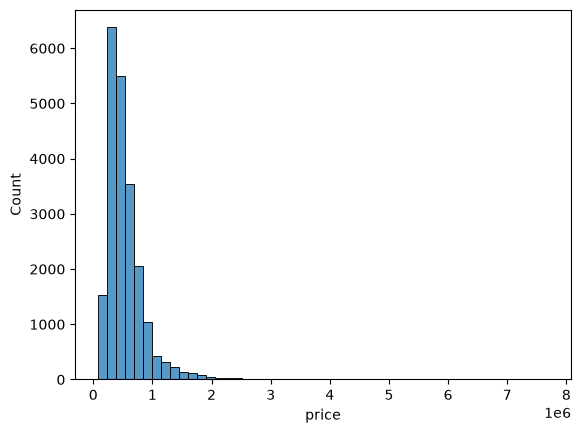

In [9]:
sns.histplot(df['price'],bins=50)
plt.show()

In [11]:
df[df['price'] > df['price'].median()].head()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,lat,long,sqft_living15,sqft_lot15,renovated
1,6414100192,538000.0,3.0,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,47.7210,-122.319,1690,7639,1
3,2487200875,604000.0,4.0,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,47.5208,-122.393,1360,5000,0
4,1954400510,510000.0,3.0,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,47.6168,-122.045,1800,7503,0
5,7237550310,1225000.0,4.0,4.50,5420,101930,1.0,0,0,3,11,3890,1530,2001,47.6561,-122.005,4760,101930,0
10,1736800520,662500.0,3.0,2.50,3560,9796,1.0,0,0,3,8,1860,1700,1965,47.6007,-122.145,2210,8925,0


In [12]:
df.corr(numeric_only=True)['price'].sort_values(ascending=False)

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525885
view             0.397293
sqft_basement    0.323816
bedrooms         0.316058
lat              0.307003
waterfront       0.266369
floors           0.256794
renovated        0.126092
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
id              -0.016762
Name: price, dtype: float64

In [13]:
df.corr(numeric_only=True)

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,lat,long,sqft_living15,sqft_lot15,renovated
id,1.000000,-0.016762,0.002513,0.005234,-0.012258,-0.132109,0.018525,-0.002721,0.011592,-0.023783,0.008130,-0.010842,-0.005151,0.021380,-0.001891,0.020799,-0.002901,-0.138798,-0.016943
price,-0.016762,1.000000,0.316058,0.525885,0.702035,0.089661,0.256794,0.266369,0.397293,0.036362,0.667434,0.605567,0.323816,0.054012,0.307003,0.021626,0.585379,0.082447,0.126092
bedrooms,0.002513,0.316058,1.000000,0.527870,0.593362,0.033451,0.183942,-0.006834,0.082508,0.023655,0.366761,0.492742,0.309344,0.160857,-0.011376,0.135546,0.404679,0.031669,0.018931
bathrooms,0.005234,0.525885,0.527870,1.000000,0.755789,0.087932,0.502462,0.063744,0.188390,-0.126263,0.665887,0.686735,0.283456,0.507013,0.024253,0.225103,0.569787,0.087544,0.050081
sqft_living,-0.012258,0.702035,0.593362,0.755789,1.000000,0.172826,0.353949,0.103818,0.284611,-0.058753,0.762704,0.876597,0.435043,0.318049,0.052529,0.240223,0.756420,0.183286,0.055094
sqft_lot,-0.132109,0.089661,0.033451,0.087932,0.172826,1.000000,-0.005201,0.021604,0.074710,-0.008958,0.113621,0.183512,0.015286,0.053080,-0.085683,0.229521,0.144608,0.718557,0.007745
floors,0.018525,0.256794,0.183942,0.502462,0.353949,-0.005201,1.000000,0.023698,0.029444,-0.263768,0.458183,0.523885,-0.245705,0.489319,0.049614,0.125419,0.279885,-0.011269,0.006260
waterfront,-0.002721,0.266369,-0.006834,0.063744,0.103818,0.021604,0.023698,1.000000,0.401857,0.016653,0.082775,0.072075,0.080588,-0.026161,-0.014274,-0.041910,0.086463,0.030703,0.093294
view,0.011592,0.397293,0.082508,0.188390,0.284611,0.074710,0.029444,0.401857,1.000000,0.045990,0.251321,0.167649,0.276947,-0.053440,0.006157,-0.078400,0.280439,0.072575,0.104062
condition,-0.023783,0.036362,0.023655,-0.126263,-0.058753,-0.008958,-0.263768,0.016653,0.045990,1.000000,-0.144674,-0.158214,0.174105,-0.361417,-0.014941,-0.106500,-0.092824,-0.003406,-0.060139


skew before: 4.024069144684714
skew after:  0.4280724755759251


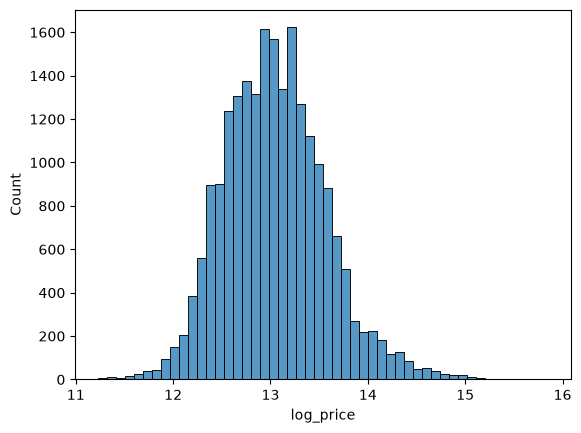

In [16]:
import numpy as np

df["log_price"] = np.log(df["price"])

print("skew before:", df["price"].skew())
print("skew after: ", df["log_price"].skew())

sns.histplot(df["log_price"], bins=50)
plt.show()

In [17]:
corr = df.drop(columns=["price", "log_price", "id"], errors="ignore").corr(numeric_only=True)

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = upper.stack().sort_values(key=abs, ascending=False)

print(pairs.head(10))

sqft_living  sqft_above       0.876597
             grade            0.762704
             sqft_living15    0.756420
grade        sqft_above       0.755923
bathrooms    sqft_living      0.755789
sqft_above   sqft_living15    0.731870
sqft_lot     sqft_lot15       0.718557
grade        sqft_living15    0.713202
bathrooms    sqft_above       0.686735
             grade            0.665887
dtype: float64


## EDA Findings
`sqft_living` has the highest correlation with price (0.70), followed by `grade` (0.67). `sqft_living` and `sqft_above` are also highly correlated (0.88). 
Price is right-skewed (4.02 on the full dataset and 4.00 on the training data), but log transformation reduces this to 0.43. No features will be removed based on correlation alone. The `id` column will be used for grouped train/test splitting but excluded from model training.
